repository root: <repo>
total files: 24608
suspect (<= 4096 bytes): 5914
SWOT overpasses: 192
SWOT time range: 2024-11-11 01:07:13 to 2026-04-17 15:54:43


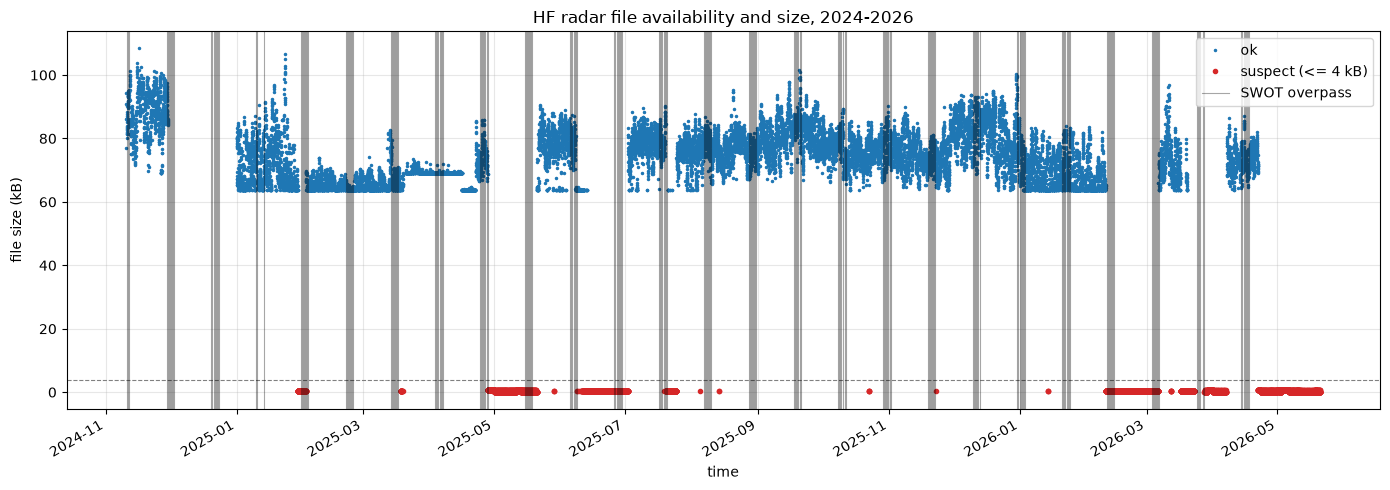

,time,name,size_bytes
0,2025-01-29 10:00:00,radar_sa_202501291000_combined_hyddoa.nc,506
1,2025-01-29 10:30:00,radar_sa_202501291030_combined_hyddoa.nc,506
2,2025-01-29 11:00:00,radar_sa_202501291100_combined_hyddoa.nc,506
3,2025-01-29 11:30:00,radar_sa_202501291130_combined_hyddoa.nc,506
4,2025-01-29 14:00:00,radar_sa_202501291400_combined_hyddoa.nc,506
...,...,...,...
5909,2026-05-20 21:30:00,radar_sa_202605202130_combined_hyddoa.nc,161
5910,2026-05-20 22:00:00,radar_sa_202605202200_combined_hyddoa.nc,161
5911,2026-05-20 22:30:00,radar_sa_202605202230_combined_hyddoa.nc,161
5912,2026-05-20 23:00:00,radar_sa_202605202300_combined_hyddoa.nc,161


In [8]:
from pathlib import Path
import re
import pandas as pd
import xarray as xr

import matplotlib.pyplot as plt

# Resolve the repository root whether the notebook runs from the root or notebooks/.
working_directory = Path.cwd()
repo_root = (
    working_directory
    if (working_directory / "data/raw/hf_radar").is_dir()
    else working_directory.parent
)
base = repo_root / "data/raw/hf_radar"
swot_zarr_path = repo_root / "data/processed/swot_filtered_velocity.zarr"

# Collect HF radar files for 2024-2026, including date-stamped subdirectories.
files = sorted(
    file_path
    for year in ("2024", "2025", "2026")
    for file_path in (base / year).rglob("*.nc")
)

# Derive timestamps from filenames: match the first YYYYMMDD(HHMM) block.
pattern = re.compile(r"(\d{4})(\d{2})(\d{2})[_T\-]?(\d{2})?(\d{2})?")

records = []
for file_path in files:
    match = pattern.search(file_path.name)
    if not match:
        continue
    year, month, day, hour, minute = match.groups()
    timestamp = pd.Timestamp(
        int(year),
        int(month),
        int(day),
        int(hour or 0),
        int(minute or 0),
    )
    records.append(
        {
            "file": file_path,
            "name": file_path.name,
            "time": timestamp,
            "size_bytes": file_path.stat().st_size,
        }
    )

if not records:
    raise FileNotFoundError(
        f"No timestamped NetCDF files found recursively below {base}."
    )

df = pd.DataFrame(records).sort_values("time").reset_index(drop=True)

# Load SWOT overpass timestamps from the processed velocity archive.
if not swot_zarr_path.exists():
    raise FileNotFoundError(f"SWOT archive not found: {swot_zarr_path}")
with xr.open_zarr(swot_zarr_path, consolidated=True) as swot_ds:
    swot_times = pd.to_datetime(swot_ds["time"].values)

# Flag suspect files: 4 kB (4096 bytes) or smaller -> likely empty/corrupted.
SUSPECT_MAX_BYTES = 4096
df["size_kb"] = df["size_bytes"] / 1024
df["suspect"] = df["size_bytes"] <= SUSPECT_MAX_BYTES

print(f"repository root: {repo_root}")
print(f"total files: {len(df)}")
print(f"suspect (<= {SUSPECT_MAX_BYTES} bytes): {df['suspect'].sum()}")
print(f"SWOT overpasses: {len(swot_times)}")
print(f"SWOT time range: {swot_times.min()} to {swot_times.max()}")

# Plot file size against time; suspect files and SWOT overpasses highlighted.
fig, ax = plt.subplots(figsize=(14, 5))
ok = df[~df["suspect"]]
bad = df[df["suspect"]]
ax.plot(ok["time"], ok["size_kb"], ".", ms=3, color="tab:blue", label="ok")
ax.plot(bad["time"], bad["size_kb"], ".", ms=6, color="tab:red", label="suspect (<= 4 kB)")
ax.axhline(SUSPECT_MAX_BYTES / 1024, color="grey", ls="--", lw=0.8)

for overpass_index, swot_time in enumerate(swot_times):
    ax.axvline(
        swot_time,
        color="black",
        alpha=0.35,
        linewidth=0.8,
        label="SWOT overpass" if overpass_index == 0 else "_nolegend_",
    )

ax.set_xlabel("time")
ax.set_ylabel("file size (kB)")
ax.set_title("HF radar file availability and size, 2024-2026")
ax.legend(loc="upper right")
ax.grid(alpha=0.3)
fig.autofmt_xdate()
plt.tight_layout()
plt.show()

# List of suspect files.
suspect_files = bad[["time", "name", "size_bytes"]].reset_index(drop=True)
display(suspect_files)